# k-Means with the Penguins dataset (k = 3)

This notebook clusters penguins into 3 groups using only their physical measurements - k-Means never sees the species labels. We then check how well those unsupervised clusters line up with the 3 actual species in the data (Adelie, Chinstrap, Gentoo).

We pick `k = 3` because we happen to know there are 3 species here. In real unsupervised problems you usually don't know the "true" number of groups - this is a nice sanity check of what k-Means can do when we *do* know the answer.

# Import the libraries and dataset

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import adjusted_rand_score

%matplotlib inline

# Load and clean the data

A handful of rows have missing measurements, so we drop those before clustering.

In [2]:
df = pd.read_csv('data/penguins.csv')
df = df.dropna().reset_index(drop=True)
df['species'].value_counts()

species
Adelie       146
Gentoo       119
Chinstrap     68
Name: count, dtype: int64

# Select and scale features

k-Means groups points by distance, so features need to be on comparable scales. `body_mass_g` is measured in the thousands while `bill_depth_mm` is in the tens - without scaling, body mass would dominate the distance calculation just because of its units, not because it's more informative. We standardize every feature to mean 0 and standard deviation 1 before clustering.

In [3]:
features = ['bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g']
X = df[features]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Algorithm

We set `k = 3` since we know there are 3 species in this dataset, then fit k-Means on the scaled measurements only - no species information goes in.

In [4]:
model = KMeans(n_clusters=3, n_init=10, random_state=42)
model.fit(X_scaled)

df['cluster'] = model.labels_
df[['species', 'cluster']].head()

,species,cluster
0,Adelie,0
1,Adelie,0
2,Adelie,0
3,Adelie,0
4,Adelie,0


# Compare clusters to species

k-Means only ever produces cluster numbers (0, 1, 2) - it has no concept of "Adelie" or "Gentoo". A cross-tabulation shows how the 3 clusters are actually split across the 3 real species.

In [5]:
crosstab = pd.crosstab(df['species'], df['cluster'])
crosstab

cluster,0,1,2
species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


## Turning this into a score

Because cluster numbers are arbitrary (cluster `0` could just as easily have been called cluster `2`), we first match each cluster to whichever species it overlaps with the most, then measure what fraction of penguins land in the "right" cluster under that matching.

We also compute the **Adjusted Rand Index (ARI)**, a standard metric for comparing two groupings - here, our clusters vs. the true species - that is immune to label numbering and corrects for agreement you'd expect by pure chance. An ARI of `1.0` means a perfect match, and `0.0` means no better than a random grouping.

In [6]:
# For each cluster, find the species it contains the most of
cluster_to_species = crosstab.idxmax(axis=0)
df['predicted_species'] = df['cluster'].map(cluster_to_species)

matched_accuracy = (df['predicted_species'] == df['species']).mean()
ari = adjusted_rand_score(df['species'], df['cluster'])

print(f"Matched accuracy: {matched_accuracy:.1%}")
print(f"Adjusted Rand Index: {ari:.3f}")

Matched accuracy: 91.9%
Adjusted Rand Index: 0.799


# Plot: actual species vs. discovered clusters

Side-by-side scatter plots of two measurements. If k-Means is doing a good job, the cluster-colored plot (right) should look similar in shape to the species-colored plot (left), even though clustering never saw the species labels.

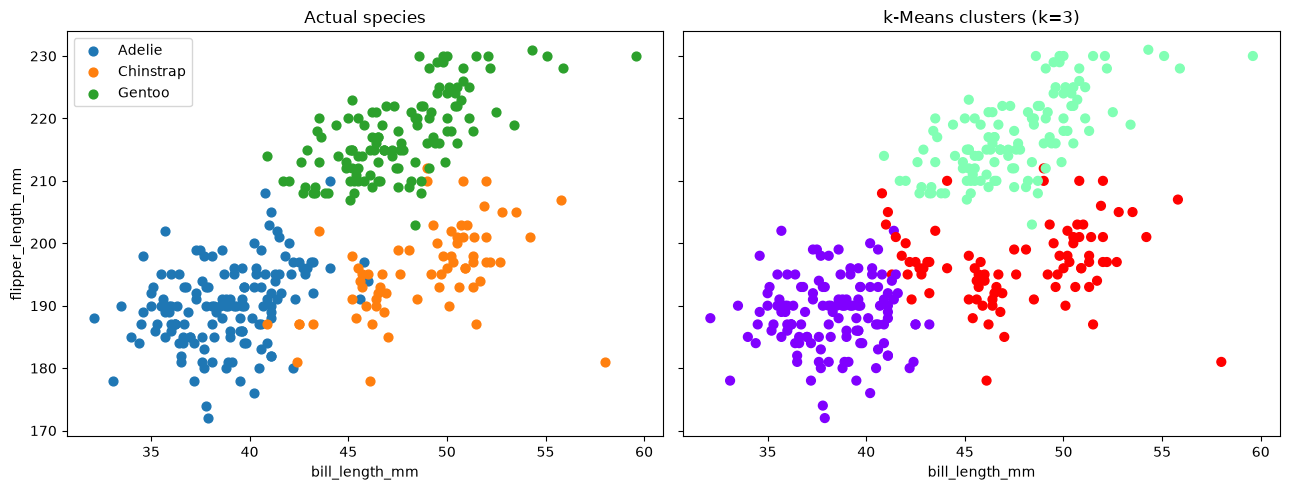

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharex=True, sharey=True)

species_colors = {'Adelie': 'tab:blue', 'Chinstrap': 'tab:orange', 'Gentoo': 'tab:green'}
for species, group in df.groupby('species'):
    axes[0].scatter(group['bill_length_mm'], group['flipper_length_mm'],
                     label=species, color=species_colors[species], s=40)
axes[0].set_title('Actual species')
axes[0].set_xlabel('bill_length_mm')
axes[0].set_ylabel('flipper_length_mm')
axes[0].legend()

axes[1].scatter(df['bill_length_mm'], df['flipper_length_mm'],
                c=df['cluster'], cmap='rainbow', s=40)
axes[1].set_title('k-Means clusters (k=3)')
axes[1].set_xlabel('bill_length_mm')

plt.tight_layout()

# Takeaway

Gentoo penguins have noticeably longer flippers than the other two species, so k-Means tends to separate them out cleanly. Adelie and Chinstrap overlap more on `bill_length_mm` and `flipper_length_mm` alone (they're more easily told apart by `bill_depth_mm`, which is included in the clustering but not shown in this 2D plot), so expect most of the mismatches in the cross-tabulation to be between those two species rather than involving Gentoo.

The bigger idea: k-Means had zero knowledge of species, yet because the measurements themselves are genuinely informative, unsupervised clustering recovers a grouping that substantially agrees with the real biological categories.